# 상품 분류 헤드 학습 — 실행 드라이버

`fashion_clip` 백본을 **동결**하고 그 위 선형 헤드만 학습한다.
지시서 `../CLASSIFIER_FINETUNE_BRIEF.md`, 설계 `.claude/plans/ai/CH014-class-finetune.md`.

## ⚠️ 이 노트북은 얇은 드라이버다

무거운 단계는 전부 옆의 `.py` 스크립트가 하고, 여기서는 **호출하고 결과 표를 보는 것만** 한다.
브리핑 §3-1: 원격 Jupyter 커널은 연결이 끊기면 죽는다. 오래 걸리는 단계(scan, 임베딩 추출)는
**`tmux` 안에서 같은 명령을 터미널로 돌리는 걸 권장**한다 — 아래 각 셀이 실행할 명령을
그대로 찍어 주므로 복사해서 쓰면 된다.

In [1]:
import sys
print(sys.executable)

/home/j-i15a108/work/.venv-aihub/bin/python


In [2]:
import subprocess
print(subprocess.run(["whoami"], capture_output=True, text=True).stdout)
print(subprocess.run(["bash", "-c", "echo $HOME"], capture_output=True, text=True).stdout)
print(subprocess.run(["find", "/home", "-maxdepth", "4", "-name", "aihub_dataset.py"], capture_output=True, text=True).stdout)

j-i15a108

/home/j-i15a108




In [4]:
import subprocess
import sys
import threading
import time


def run(script, *args, heartbeat_every=30):
    """스크립트를 실행하고 출력을 실시간으로 보여준다.

    스크립트 자체가 한동안 아무것도 안 찍어도(전처리 구간 등) heartbeat_every초마다
    '아직 실행 중' 한 줄을 찍어서 죽었는지 살았는지 구분할 수 있게 한다.
    """
    cmd = [sys.executable, str(HERE / script), *[str(a) for a in args]]
    print("$ " + " ".join(cmd) + "\n", flush=True)
    start = time.time()

    process = subprocess.Popen(
        cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, bufsize=1, encoding="utf-8",
    )

    stop_heartbeat = threading.Event()

    def heartbeat():
        while not stop_heartbeat.wait(heartbeat_every):
            print(f"  ... 아직 실행 중 (경과 {time.time() - start:.0f}초)", flush=True)

    hb_thread = threading.Thread(target=heartbeat, daemon=True)
    hb_thread.start()

    try:
        for line in process.stdout:
            print(f"[{time.time() - start:7.1f}s] {line}", end="", flush=True)
    finally:
        stop_heartbeat.set()

    process.wait()
    elapsed = time.time() - start
    status = "성공" if process.returncode == 0 else f"⚠ 실패(returncode={process.returncode})"
    print(f"\n{status} — 총 {elapsed:.1f}초", flush=True)
    return process

In [3]:
# ── 여기만 서버 환경에 맞게 고친다 ────────────────────────────────────
import json
import subprocess
import sys
from pathlib import Path

# 이 노트북이 있는 폴더를 **절대경로로** 적는다.
# 상대경로나 Path.cwd()를 쓰지 않는 이유(브리핑 §3-1): VS Code에서 원격 커널에 붙으면
# 파일은 로컬·실행은 원격이라 상대경로가 원격 기준으로 해석돼 조용히 어긋난다.
HERE = Path("/home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune")
assert (HERE / "aihub_dataset.py").exists(), f"HERE가 틀렸다: {HERE}"

CLOTHES_ROOT = Path("/home/j-i15a108/work/aihub/008.의류_통합_데이터")
ACCESSORY_ROOT = Path("/home/j-i15a108/work/aihub/extracted/accessory_fixed")
IMAGE_ROOT = Path("/home/j-i15a108/work/aihub")
ARTIFACTS = HERE / "artifacts"

VARIANT = "masked"
SHORT_PANTS_MAX_CM = None  # scan 히스토그램을 보고 정할 것. None이면 SHORT_PANTS 파생 안 함

ARTIFACTS.mkdir(parents=True, exist_ok=True)

print("good")

def run(script, *args):
    """스크립트를 실행하고 출력을 그대로 보여준다. 실행할 명령도 같이 찍는다."""
    cmd = [sys.executable, str(HERE / script), *[str(a) for a in args]]
    print("$ " + " ".join(cmd) + "\n")
    result = subprocess.run(cmd, capture_output=True, text=True, encoding="utf-8")
    print(result.stdout)
    if result.returncode != 0:
        print("--- stderr ---")
        print(result.stderr)
    return result


good


## STEP 1 — scan (착수 게이트 2개)

이미지 없이 라벨 JSON만 훑는다. 확인할 것:
1. **게이트 1** `model.type`의 front/back이 상품컷인가 착용샷인가 → 찍힌 경로를 직접 열어 볼 것
2. **게이트 2** `clothes.color`에 Navy가 실재하는가

덤으로 `pants_length` 히스토그램(SHORT_PANTS 임계), polo 건수, 그룹 크기 분포가 나온다.
550k라 오래 걸린다 — 감만 볼 거면 `--limit 5000`을 붙일 것.

게이트 2 색상 표는 다색 콤마 조합("Black,White" 등)까지 다 세면 수백 줄이 나온다. 기본으로
상위 20개만 찍고 나머지는 합계 한 줄로 접는다(`--color-top`, 0이면 전체 출력).

In [5]:
CLOTHES_ROOT = Path("/home/j-i15a108/work/aihub/extracted/clothes")
ACCESSORY_ROOT = Path("/home/j-i15a108/work/aihub/extracted/accessory_fixed")
IMAGE_ROOT = Path("/home/j-i15a108/work/aihub/extracted/images")

run(
    "aihub_dataset.py",
    "scan",
    "--root",
    CLOTHES_ROOT,
    "--accessory-root",
    ACCESSORY_ROOT,
    "--out",
    ARTIFACTS / "scan.txt",
)

$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_dataset.py scan --root /home/j-i15a108/work/aihub/extracted/clothes --accessory-root /home/j-i15a108/work/aihub/extracted/accessory_fixed --out /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts/scan.txt

[    9.1s]   ... 50,000개 읽음
[   17.0s] 루트          : /home/j-i15a108/work/aihub/extracted/clothes
[   17.0s] 라벨 JSON     : 55,058개 (파싱 실패 0)
[   17.0s] 유효 레코드   : 55,058
[   17.0s] SHORT_PANTS 임계 : 미설정(None)
[   17.0s] 
[   17.0s] ==============================================================================
[   17.0s] 게이트 1 — metadata.model.type (촬영유형)
[   17.0s] ==============================================================================
[   17.0s] 값     건수    비율 
[   17.0s] -----  ------  -----
[   17.0s] wear   32,892  59.7%
[   17.0s] front  11,192  20.3%
[   17.0s] back   10,974  19.9%
[   17.0s] 
[   17.0s] >>> 판정은 사람이 

<Popen: returncode: 0 args: ['/home/j-i15a108/work/.venv-aihub/bin/python', ...>

## STEP 2 — index (라벨 인덱스 + 분할 + 층화 샘플)

여기서 **어떤 이미지를 받을지**가 정해진다. 소스별 비중은 `--category-cap`(의류)과
`--accessory-cap`(액세서리)으로 조절한다. 출력 맨 아래 "소스별 비중" 표를 보고 다시 돌리면 된다.

카테고리 상한은 **엄수**된다(색상 쿼터가 상한을 넘기지 못한다). 옛 동작이 필요하면
`--allow-cap-overflow`.

In [6]:
index_args = [
    "index",
    "--root",
    CLOTHES_ROOT,
    "--accessory-root",
    ACCESSORY_ROOT,
    "--out-dir",
    ARTIFACTS,
    "--category-cap",
    3000,
    "--accessory-cap",
    3000,
    "--color-cap",
    2000,
    "--eval-cap",
    100,
    "--accessory-shot-type",   # ← 추가
    "product",                 # ← 추가
]
if SHORT_PANTS_MAX_CM is not None:
    index_args += ["--short-pants-max-cm", SHORT_PANTS_MAX_CM]

run("aihub_dataset.py", *index_args)

$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_dataset.py index --root /home/j-i15a108/work/aihub/extracted/clothes --accessory-root /home/j-i15a108/work/aihub/extracted/accessory_fixed --out-dir /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts --category-cap 3000 --accessory-cap 3000 --color-cap 2000 --eval-cap 100 --accessory-shot-type product

[    8.7s]   ... 50,000개 읽음
[   17.4s] 라벨 JSON     : 97,312개 (파싱 실패 0)
[   17.4s] 인덱스 레코드 : 55,519  → /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts/index.jsonl
[   17.4s] 층화 샘플     : 31,204  → /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts/sample.jsonl
[   17.4s] 
[   17.4s] 액세서리 촬영유형 필터 'product' 적용 — 39,332건 제외(다른 촬영유형)
[   17.4s] 
[   17.4s] split  전체    층화 샘플  그룹 수
[   17.4s] -----  ------  ---------  -------
[   17.4s] train  44,380  28,329     35,136 


<Popen: returncode: 0 args: ['/home/j-i15a108/work/.venv-aihub/bin/python', ...>

### 마스크 크롭이 제대로 되는지 눈으로 확인 (선택)

`__raw.jpg` / `__masked.jpg` 쌍을 몇 장 떨군다. 배경이 실제로 흰색으로 치환됐는지 본다.

In [ ]:
run(
    "aihub_preprocess.py",
    "--index",
    ARTIFACTS / "sample.jsonl",
    "--label-root",
    CLOTHES_ROOT,
    "--image-root",
    IMAGE_ROOT,
    "--out-dir",
    ARTIFACTS / "crop_preview",
    "--count",
    8,
)

## STEP 3 — 임베딩 추출 (GPU, 파이프라인에서 유일하게 무거운 단계)

**이 셀은 tmux에서 돌리는 걸 강력히 권장한다.** 5만 장이면 GPU에서도 수십 분이다.
출력된 `$ ...` 명령을 복사해 터미널에서 실행해도 결과는 같다.

브리핑 §3(A)가 요구하는 **입력 변형 2개 비교**를 위해 `masked`와 `raw`를 둘 다 뽑는다.

In [7]:
import shutil
import sys

import torch

print("python 실행 경로:", sys.executable)
print("torch:", torch.__version__, "| cuda available:", torch.cuda.is_available())

if not torch.cuda.is_available():
    raise RuntimeError(
        "CUDA를 못 잡았다 — 커널이 'aihub (py312)'인지 확인할 것. "
        "python 경로가 .venv-aihub가 아니면 커널을 바꾸고 재시작해야 한다."
    )

print("GPU:", torch.cuda.get_device_name(0))
free, total = torch.cuda.mem_get_info()
print(f"VRAM 여유/전체: {free/1e9:.1f} / {total/1e9:.1f} GB")

for name, path in [("CLOTHES_ROOT", CLOTHES_ROOT), ("ACCESSORY_ROOT", ACCESSORY_ROOT),
                    ("IMAGE_ROOT", IMAGE_ROOT)]:
    assert path.exists(), f"{name} 경로가 없다: {path}"

sample_path = ARTIFACTS / "sample.jsonl"
assert sample_path.exists(), f"sample.jsonl이 없다 — STEP 2(index)를 먼저 돌릴 것: {sample_path}"

free_disk_gb = shutil.disk_usage(ARTIFACTS).free / 1e9
print(f"디스크 여유공간: {free_disk_gb:.1f} GB")
print("사전 점검 통과 — STEP 3 진행 가능")

python 실행 경로: /home/j-i15a108/work/.venv-aihub/bin/python
torch: 2.11.0+cu128 | cuda available: True
GPU: NVIDIA L40S
VRAM 여유/전체: 32.1 / 47.7 GB
디스크 여유공간: 16672.5 GB
사전 점검 통과 — STEP 3 진행 가능


In [8]:
import time

BATCH_SIZE = 64      # OOM 나면 낮추고, VRAM 여유 있으면 128까지
OVERWRITE = True     # 이미 있는 .npy를 다시 만들려면 True

results = []
loop_start = time.time()

for split in ("train", "val", "test"):
    for variant in ("masked", "raw"):
        args = [
            "--index", ARTIFACTS / "sample.jsonl",
            "--label-root", CLOTHES_ROOT,
            "--accessory-label-root", ACCESSORY_ROOT,
            "--image-root", IMAGE_ROOT,
            "--out-dir", ARTIFACTS,
            "--split", split,
            "--variant", variant,
            "--batch-size", BATCH_SIZE,
        ]
        if OVERWRITE:
            args.append("--overwrite")

        t0 = time.time()
        proc = run("aihub_embed.py", *args)
        elapsed = time.time() - t0
        results.append((split, variant, proc.returncode, elapsed))

        if proc.returncode != 0:
            print(f"⚠ {split}/{variant} 실패(code={proc.returncode}) — 나머지는 계속 진행한다")

total_elapsed = time.time() - loop_start
print(f"\n=== 전체 완료 — 총 {total_elapsed/60:.1f}분 ===")
for split, variant, code, elapsed in results:
    status = "OK" if code == 0 else f"FAIL({code})"
    print(f"  {split:5s} {variant:6s} {elapsed/60:6.1f}분  {status}")

$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_embed.py --index /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts/sample.jsonl --label-root /home/j-i15a108/work/aihub/extracted/clothes --accessory-label-root /home/j-i15a108/work/aihub/extracted/accessory_fixed --image-root /home/j-i15a108/work/aihub/extracted/images --out-dir /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts --split train --variant masked --batch-size 64

[    1.0s] 이미 있다(건너뜀): /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts/train_masked.npy  — 다시 만들려면 --overwrite

성공 — 총 1.2초
$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_embed.py --index /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts/sample.jsonl --label-root /home/j-i15a10

In [16]:
# STEP 3.5 (선택) — ViT 파인튜닝용 입력 텐서 캐싱. 선형 헤드만 볼 거면 건너뛴다.
# 모델은 안 실어서 GPU 없이도 돈다 — train만 캐시해도 되지만 val/test도 같은 인터페이스로
# 맞춰 두면 파인튜닝 스크립트가 셋 다 같은 방식으로 읽을 수 있다.
for split in ("train", "val", "test"):
    run(
        "aihub_cache_pixels.py",
        "--index",
        ARTIFACTS / "sample.jsonl",
        "--label-root",
        CLOTHES_ROOT,
        "--accessory-label-root",
        ACCESSORY_ROOT,
        "--image-root",
        IMAGE_ROOT,
        "--out-dir",
        ARTIFACTS,
        "--split",
        split,
        "--variant",
        VARIANT,
    )

$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_cache_pixels.py --index /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts/sample.jsonl --label-root /home/j-i15a108/work/aihub/extracted/clothes --accessory-label-root /home/j-i15a108/work/aihub/extracted/accessory_fixed --image-root /home/j-i15a108/work/aihub/extracted/images --out-dir /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts --split train --variant masked

[    4.3s] Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.
  ... 아직 실행 중 (경과 30초)
  ... 아직 실행 중 (경과 60초)
  ... 아직 실행 중 (경과 90초)
  ... 아직 실행 중 (경과 120초)
[  144.6

In [17]:
### 정합성 점검
import numpy as np

npy = np.load(ARTIFACTS / "train_masked.npy")
with open(ARTIFACTS / "train_masked.jsonl", encoding="utf-8") as f:
    n_rows = sum(1 for _ in f)

print(npy.shape, n_rows)
print("일치 ✅" if npy.shape[0] == n_rows else "⚠ 불일치 — --overwrite로 다시")

(26445, 512) 26445
일치 ✅


## STEP 4 — 파인튜닝
#### Last-N 언프리즈 (GPU)
#### LoRA 파인튜닝
#### 헤드 학습 (CPU, 수 초)

- `color` : 14-way 로지스틱 회귀 (커버리지 100%라 가장 확실하다)
- `polo`  : TSHIRT vs SHIRT 이진. 35-way를 건드리지 않아 회귀 위험이 없다
- `category` : 커버 클래스 N-way (미커버 클래스는 계속 zero-shot)

`--class-weight balanced`가 층화 상한과 함께 쓰는 **두 번째 비중 손잡이**다.

In [27]:
### last-N 언프리즈 (ViT few layer만 해동 / 나머진 freeze) 
run(
    "aihub_finetune_vit.py",
    "--pixel-cache-dir", ARTIFACTS,
    "--task", "category",
    "--variant", VARIANT,
    "--unfreeze-layers", 4,
    "--epochs", 10,
    "--batch-size", 32,
)

$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_finetune_vit.py --pixel-cache-dir /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts --task category --variant masked --unfreeze-layers 4 --epochs 10 --batch-size 32

  ... 아직 실행 중 (경과 30초)
[   30.9s] task=category variant=masked unfreeze_layers=4 train=22,758 val=932 test=933 classes=11
[   30.9s]   epoch 1/10  loss=0.8567  val_acc=0.7994
[   50.9s]   epoch 2/10  loss=0.4537  val_acc=0.8197
  ... 아직 실행 중 (경과 60초)
[   71.0s]   epoch 3/10  loss=0.3466  val_acc=0.8112
  ... 아직 실행 중 (경과 90초)
[   91.1s]   epoch 4/10  loss=0.2434  val_acc=0.8090
[  111.1s]   epoch 5/10  loss=0.1501  val_acc=0.7940
  ... 아직 실행 중 (경과 120초)
[  131.3s]   epoch 6/10  loss=0.0913  val_acc=0.8197
  ... 아직 실행 중 (경과 150초)
[  151.5s]   epoch 7/10  loss=0.0542  val_acc=0.8090
[  171.7s]   epoch 8/10  loss=0.0379  val_acc=0.8079
  ... 아직 실행 중 (경과 180초)
[  191.8s]

<Popen: returncode: 0 args: ['/home/j-i15a108/work/.venv-aihub/bin/python', ...>

In [31]:
### LoRA — 
run(
    "aihub_finetune_lora.py",
    "--pixel-cache-dir", ARTIFACTS,
    "--task", "category",
    "--variant", VARIANT,
    "--r", 8,
    "--alpha", 16,
    "--epochs", 10,
    "--batch-size", 32,
)

$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_finetune_lora.py --pixel-cache-dir /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts --task category --variant masked --r 8 --alpha 16 --epochs 10 --batch-size 32

  ... 아직 실행 중 (경과 30초)
[   35.4s] task=category variant=masked lora_r=8 alpha=16 train=22,758 val=932 test=933 classes=11
[   35.4s] 학습 대상 파라미터: 689,664 / 151,572,225 (0.46%)
[   35.4s]   epoch 1/10  loss=0.8480  val_acc=0.7972
  ... 아직 실행 중 (경과 60초)
[   62.0s]   epoch 2/10  loss=0.4851  val_acc=0.8176
[   88.6s]   epoch 3/10  loss=0.4226  val_acc=0.8122
  ... 아직 실행 중 (경과 90초)
[  112.8s]   epoch 4/10  loss=0.3678  val_acc=0.8187
  ... 아직 실행 중 (경과 120초)
[  137.5s]   epoch 5/10  loss=0.3161  val_acc=0.8165
  ... 아직 실행 중 (경과 150초)
[  162.4s]   epoch 6/10  loss=0.2703  val_acc=0.8176
  ... 아직 실행 중 (경과 180초)
[  187.8s]   epoch 7/10  loss=0.2249  val_acc=0.8058
  ... 아직 실행 

<Popen: returncode: 0 args: ['/home/j-i15a108/work/.venv-aihub/bin/python', ...>

In [43]:
run(
    "aihub_finetune_lora.py",
    "--pixel-cache-dir", ARTIFACTS,
    "--task", "category",
    "--variant", VARIANT,
    "--r", 16,
    "--alpha", 32,
    "--epochs", 10,
    "--batch-size", 32,
)

$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_finetune_lora.py --pixel-cache-dir /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts --task category --variant masked --r 16 --alpha 32 --epochs 10 --batch-size 32

  ... 아직 실행 중 (경과 30초)
[   37.7s] task=category variant=masked lora_r=16 alpha=32 train=22,758 val=932 test=933 classes=11
[   37.7s] 학습 대상 파라미터: 984,576 / 151,867,137 (0.65%)
[   37.7s]   epoch 1/10  loss=0.8392  val_acc=0.8026
  ... 아직 실행 중 (경과 60초)
[   64.7s]   epoch 2/10  loss=0.4695  val_acc=0.8230
  ... 아직 실행 중 (경과 90초)
[   92.8s]   epoch 3/10  loss=0.3912  val_acc=0.8047
[  118.7s]   epoch 4/10  loss=0.3227  val_acc=0.8219
  ... 아직 실행 중 (경과 120초)
[  146.8s]   epoch 5/10  loss=0.2586  val_acc=0.8122
  ... 아직 실행 중 (경과 150초)
[  172.3s]   epoch 6/10  loss=0.2101  val_acc=0.8122
  ... 아직 실행 중 (경과 180초)
[  196.7s]   epoch 7/10  loss=0.1627  val_acc=0.8058
  ... 아직 실

<Popen: returncode: 0 args: ['/home/j-i15a108/work/.venv-aihub/bin/python', ...>

In [11]:
# 색상 헤드는 **의류만** 쓴다. 액세서리 금속색(실버→GRAY, 골드→YELLOW, 로즈골드→PINK)은
# color.py 팔레트가 상정한 의류 색상과 시각적으로 딴판이라, 은목걸이를 회색 니트와 같은
# 클래스로 학습시키면 14-way 경계가 금속 광택 쪽으로 끌려간다.
run("aihub_train_head.py", "--artifacts", ARTIFACTS, "--task", "color",
    "--variant", VARIANT, "--source", "clothes", "--class-weight", "balanced")

# 카테고리는 반대다 — 액세서리가 HAT·SUNGLASSES·JEWELRY를 유일하게 덮으므로 둘 다 쓴다.
run("aihub_train_head.py", "--artifacts", ARTIFACTS, "--task", "category",
    "--variant", VARIANT, "--class-weight", "balanced")

# 폴로 이진 헤드는 정의상 02top_* 만 대상이라 소스 필터가 의미 없다.
run("aihub_train_head.py", "--artifacts", ARTIFACTS, "--task", "polo",
    "--variant", VARIANT, "--class-weight", "balanced")

$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_train_head.py --artifacts /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts --task color --variant masked --source clothes --class-weight balanced

[    1.5s] task=color variant=masked train=19,724 classes=13
[    1.5s] [train] n=19,724  accuracy=0.7512
[    1.5s]   클래스     precision  recall  support
[    1.5s]   BEIGE       0.683   0.600    2,117
[    1.5s]   BLACK       0.825   0.843    4,417
[    1.5s]   BLUE        0.773   0.736    3,408
[    1.5s]   BROWN       0.683   0.657    1,306
[    1.5s]   GRAY        0.707   0.695    2,411
[    1.5s]   GREEN       0.755   0.737    1,465
[    1.5s]   MIXED       0.095   1.000        7
[    1.5s]   ORANGE      0.671   0.841      233
[    1.5s]   PINK        0.810   0.744      872
[    1.5s]   PURPLE      0.607   0.743      413
[    1.5s]   RED         0.842   0.865      635
[    1.5s]

<Popen: returncode: 0 args: ['/home/j-i15a108/work/.venv-aihub/bin/python', ...>

In [12]:
### "배경 제거가 실제로 값을 하는가"와 "액세서리 섞으면 색상이 나빠지는가"를 숫자로 확인
for variant in ("masked", "raw"):
    run("aihub_train_head.py", "--artifacts", ARTIFACTS, "--task", "color",
        "--variant", variant, "--source", "clothes")

run("aihub_train_head.py", "--artifacts", ARTIFACTS, "--task", "color", "--variant", VARIANT)

$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_train_head.py --artifacts /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts --task color --variant masked --source clothes

[    1.5s] task=color variant=masked train=19,724 classes=13
[    1.5s] [train] n=19,724  accuracy=0.7512
[    1.5s]   클래스     precision  recall  support
[    1.5s]   BEIGE       0.683   0.600    2,117
[    1.5s]   BLACK       0.825   0.843    4,417
[    1.5s]   BLUE        0.773   0.736    3,408
[    1.5s]   BROWN       0.683   0.657    1,306
[    1.5s]   GRAY        0.707   0.695    2,411
[    1.5s]   GREEN       0.755   0.737    1,465
[    1.5s]   MIXED       0.095   1.000        7
[    1.5s]   ORANGE      0.671   0.841      233
[    1.5s]   PINK        0.810   0.744      872
[    1.5s]   PURPLE      0.607   0.743      413
[    1.5s]   RED         0.842   0.865      635
[    1.5s]   WHITE       0.745   0

<Popen: returncode: 0 args: ['/home/j-i15a108/work/.venv-aihub/bin/python', ...>

저장: /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts_finetune/loss_val_acc.png


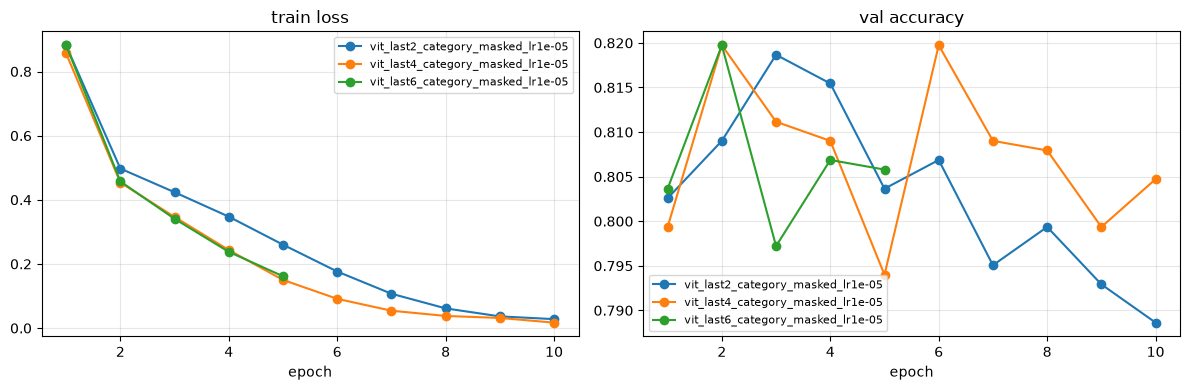

In [28]:
import matplotlib.pyplot as plt

FINETUNE_ARTIFACTS = HERE / "artifacts_finetune"

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for meta_path in sorted(FINETUNE_ARTIFACTS.glob("*/meta.json")):
    meta = json.loads(meta_path.read_text(encoding="utf-8"))
    epochs = [h["epoch"] for h in meta["history"]]
    losses = [h["train_loss"] for h in meta["history"]]
    accs = [h["val_accuracy"] for h in meta["history"]]
    label = meta_path.parent.name  # run_name — 전략별로 구분된다

    axes[0].plot(epochs, losses, marker="o", label=label)
    axes[1].plot(epochs, accs, marker="o", label=label)

axes[0].set_title("train loss")
axes[0].set_xlabel("epoch")
axes[1].set_title("val accuracy")
axes[1].set_xlabel("epoch")
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

fig.tight_layout()
out_path = FINETUNE_ARTIFACTS / "loss_val_acc.png"
fig.savefig(out_path, dpi=150)
print(f"저장: {out_path}")
plt.show()

In [44]:
run(
    "aihub_finetune_plots.py",
    "--artifacts-finetune-dir", HERE / "artifacts_finetune",
    "--baseline", "선형 프로브 val=0.8058",
    "--baseline", "zero-shot val=0.6642",
)

$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_finetune_plots.py --artifacts-finetune-dir /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts_finetune --baseline 선형 프로브 val=0.8058 --baseline zero-shot val=0.6642

[    0.3s] ⚠ 한글 폰트를 못 찾았다 — 플랏의 한글 라벨이 빈 네모로 보일 수 있다(그림 자체엔 지장 없음). 서버에 `fonts-nanum` 등을 설치하면 해결된다.
[    0.8s] ⚠ 한글 폰트를 못 찾았다 — 플랏의 한글 라벨이 빈 네모로 보일 수 있다(그림 자체엔 지장 없음). 서버에 `fonts-nanum` 등을 설치하면 해결된다.
[    0.9s] 저장: /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts_finetune/compare_LoRA.png
[    0.9s] 저장: /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts_finetune/compare_last-N_언프리즈.png
[    0.9s] 저장: /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts_finetune/compare_best_per_method.png

성공 — 총 1.0초


<Popen: returncode: 0 args: ['/home/j-i15a108/work/.venv-aihub/bin/python', ...>

compare_LoRA.png


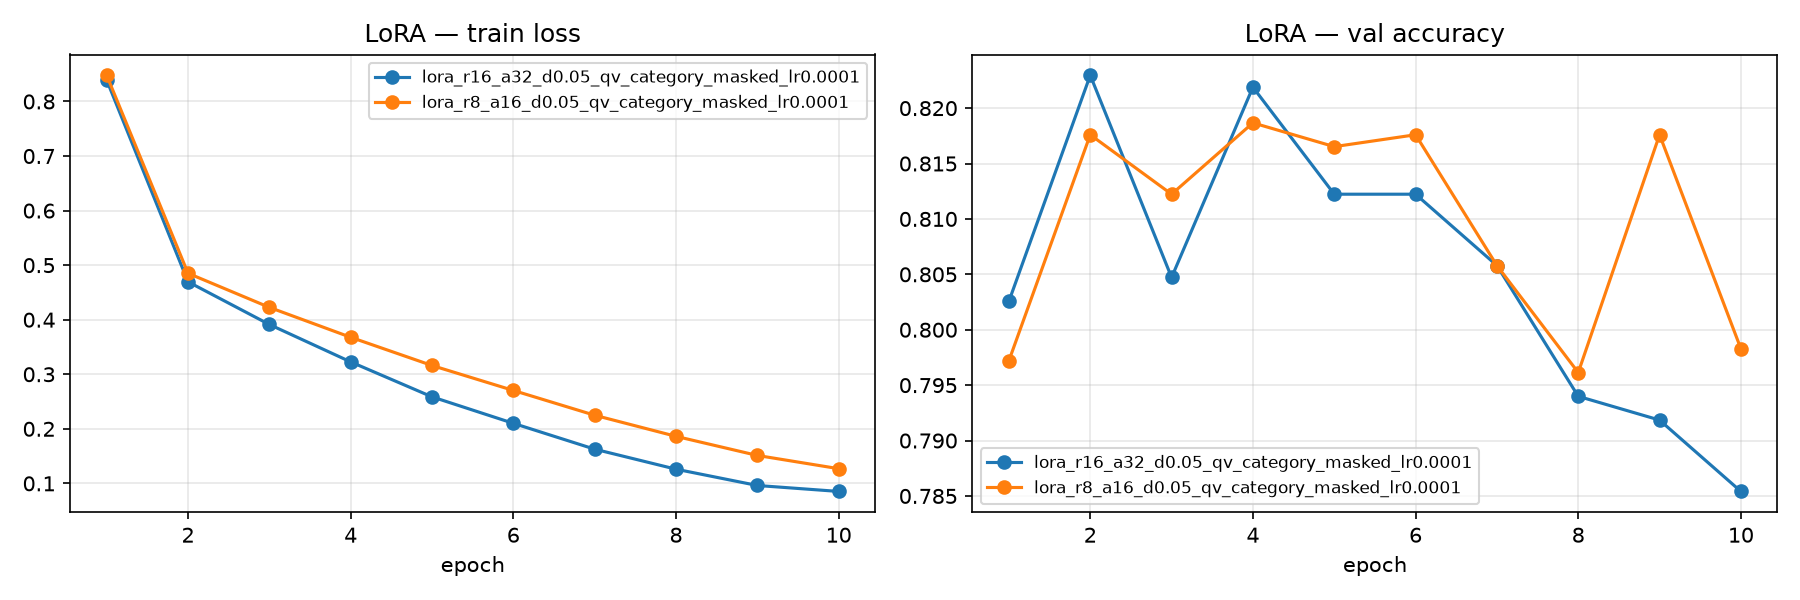

compare_best_per_method.png


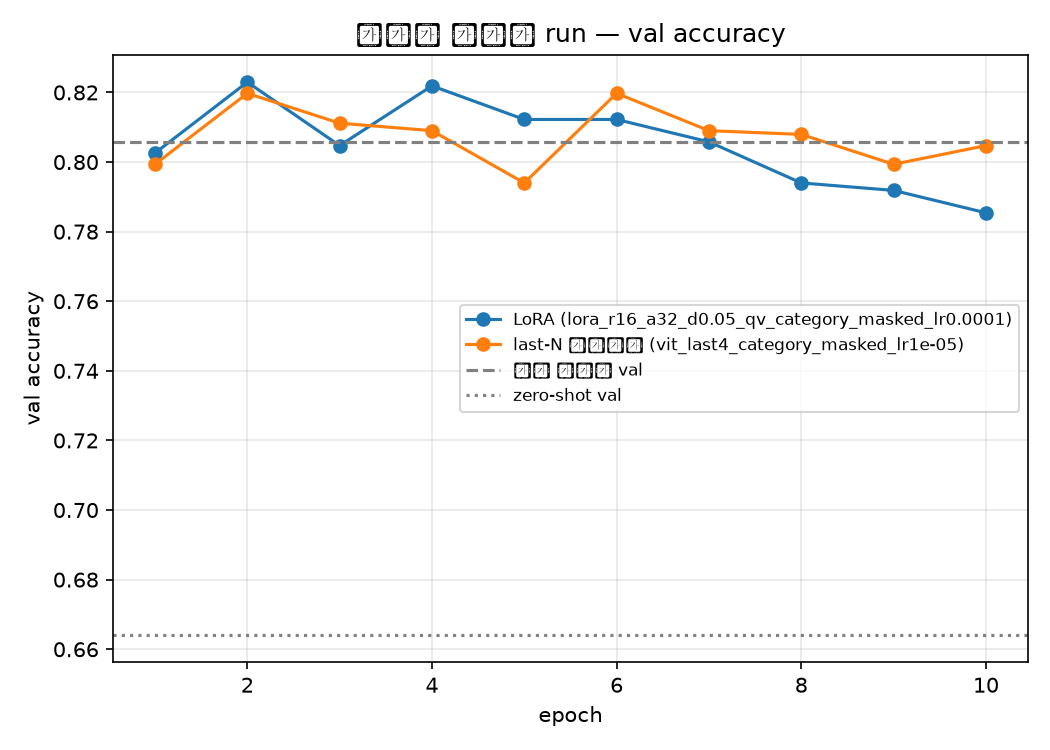

compare_last-N_언프리즈.png


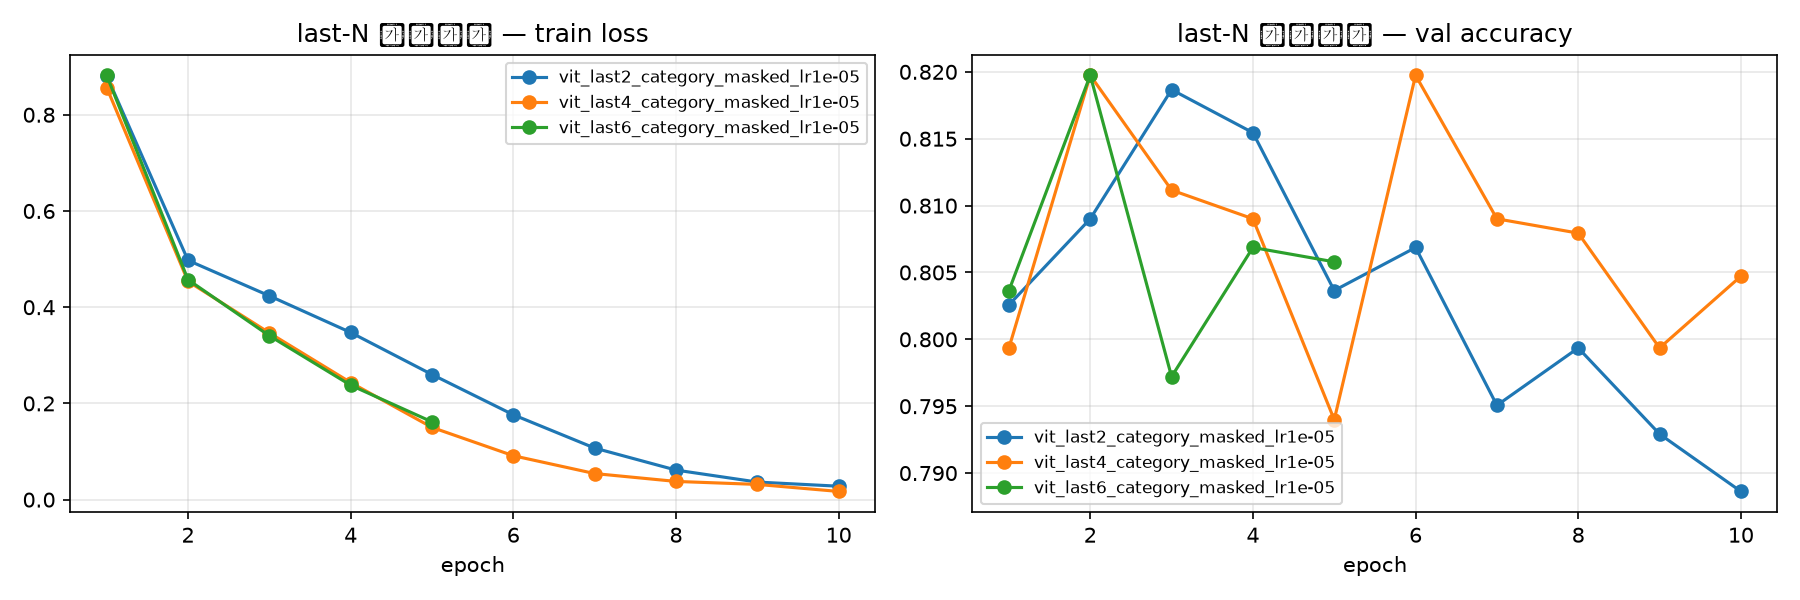

In [50]:
from IPython.display import Image, display

for png in sorted((HERE / "artifacts_finetune").glob("compare_*.png")):
    print(png.name)
    display(Image(filename=str(png)))

### 4.5 - 색상 추가 튜닝

색상에 대한 지도학습 진행
각 방법 중 베스트 모델만 추가 학습

In [ ]:
# 1) 색상 독립학습 (이미 드린 셀, 아직 안 돌렸으면 먼저)
run(
    "aihub_finetune_vit.py",
    "--pixel-cache-dir", ARTIFACTS,
    "--task", "color", "--variant", VARIANT,
    "--unfreeze-layers", 4, "--epochs", 5, "--batch-size", 32,
)
run(
    "aihub_finetune_lora.py",
    "--pixel-cache-dir", ARTIFACTS,
    "--task", "color", "--variant", VARIANT,
    "--r", 16, "--alpha", 32, "--epochs", 10, "--batch-size", 32,
)

In [54]:
# 색상 순차학습
run(
    "aihub_finetune_vit.py",
    "--pixel-cache-dir", ARTIFACTS,
    "--task", "color", "--variant", VARIANT,
    "--unfreeze-layers", 4, "--epochs", 5, "--batch-size", 32,
    "--init-checkpoint", ARTIFACTS.parent / "artifacts_finetune" / "vit_last4_category_masked_lr1e-05" / "checkpoint.pt",
)
run(
    "aihub_finetune_lora.py",
    "--pixel-cache-dir", ARTIFACTS,
    "--task", "color", "--variant", VARIANT,
    "--r", 16, "--alpha", 32, "--epochs", 10, "--batch-size", 32,
    "--init-checkpoint", ARTIFACTS.parent / "artifacts_finetune" / "lora_r16_a32_d0.05_qv_category_masked_lr0.0001" / "checkpoint.pt",
)

$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_finetune_vit.py --pixel-cache-dir /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts --task color --variant masked --unfreeze-layers 4 --epochs 5 --batch-size 32 --init-checkpoint /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts_finetune/vit_last4_category_masked_lr1e-05/checkpoint.pt

[   26.3s] task=color variant=masked unfreeze_layers=4 train=19,724 val=916 test=946 classes=13
[   26.3s] backbone 웜스타트: /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts_finetune/vit_last4_category_masked_lr1e-05/checkpoint.pt (task=category)
[   26.3s]   epoch 1/5  loss=1.2067  val_acc=0.7576
  ... 아직 실행 중 (경과 30초)
[   43.4s]   epoch 2/5  loss=0.6880  val_acc=0.7587
  ... 아직 실행 중 (경과 60초)
[   60.7s]   epoch 3/5  loss=0.5543  val_acc=0.7587
[   78.1s]   epoch 4/5  loss=0.3769  v

<Popen: returncode: 0 args: ['/home/j-i15a108/work/.venv-aihub/bin/python', ...>

## STEP 5 — 평가 (AI-Hub 홀드아웃)

둘을 항상 같이 본다. **어긋나면 우리 정답셋을 믿는다**(도메인이 다르다, 브리핑 §11).
정답셋 이미지는 gitignore라 서버에 따로 올려야 한다 — 없으면 그 섹션만 건너뛴다.

In [52]:
# 1) LoRA만 따로 — 실제 test 성능 1등 확인
run(
    "aihub_finetune_summary.py",
    "--artifacts-finetune-dir", HERE / "artifacts_finetune",
    "--pattern", "lora_*/meta.json",
    "--sort-by", "test_accuracy",
) # r=16

# 2) last-N만 따로 — N=4가 진짜 1등인지 확인
run(
    "aihub_finetune_summary.py",
    "--artifacts-finetune-dir", HERE / "artifacts_finetune",
    "--pattern", "vit_last*/meta.json",
    "--sort-by", "test_accuracy",
) # n=4

# 3) (색상까지 학습한 뒤) last-N·LoRA 각 베스트만 뽑아 토탈 비교
run(
    "aihub_finetune_summary.py",
    "--artifacts-finetune-dir", HERE / "artifacts_finetune",
    "--best-per-group", "method,task",
    "--sort-by", "test_accuracy",
    "--out", HERE / "artifacts_finetune" / "leaderboard.md",
)

$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_finetune_summary.py --artifacts-finetune-dir /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts_finetune --pattern lora_*/meta.json --sort-by test_accuracy

[    0.0s] | run | method | task | variant | best_epoch | best_val_accuracy | test_accuracy | batch_size | dropped_test_rows | dropped_val_rows | epochs | lora_alpha | lora_dropout | lora_r | lr_adapter | lr_head | model_id | target_modules | total_params | trainable_params |
[    0.0s] | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
[    0.0s] | lora_r16_a32_d0.05_qv_category_masked_lr0.0001 | LoRA | category | masked | 2 | 0.8230 | 0.8328 | 32 | 0 | 0 | 10 | 32 | 0.0500 | 16 | 0.0001 | 0.0010 | patrickjohncyh/fashion-clip | q_proj,v_proj | 151867137 | 984576 |
[    0.0s] | lora_r8_a16_d0.05_qv_categor

<Popen: returncode: 0 args: ['/home/j-i15a108/work/.venv-aihub/bin/python', ...>

In [55]:
# 리더보드 - 색상 추가
run(
    "aihub_finetune_summary.py",
    "--artifacts-finetune-dir", HERE / "artifacts_finetune",
    "--best-per-group", "method,task",
    "--sort-by", "test_accuracy",
)

$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_finetune_summary.py --artifacts-finetune-dir /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts_finetune --best-per-group method,task --sort-by test_accuracy

[    0.0s] | run | method | task | variant | best_epoch | best_val_accuracy | test_accuracy | batch_size | dropped_test_rows | dropped_val_rows | epochs | init_checkpoint | lora_alpha | lora_dropout | lora_r | lr_adapter | lr_backbone | lr_head | model_id | target_modules | total_params | trainable_params | unfreeze_layers |
[    0.0s] | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
[    0.0s] | vit_last4_category_masked_lr1e-05 | last-N 언프리즈 | category | masked | 2 | 0.8197 | 0.8424 | 32 | 0 | 0 | 10 | - | - | - | - | - | 0.0000 | 0.0010 | patrickjohncyh/fashion-clip | - | - | - | 4

<Popen: returncode: 0 args: ['/home/j-i15a108/work/.venv-aihub/bin/python', ...>

In [ ]:
# X : 학습 수렴이 안 되는 상태

# 순차학습 추가 테스트 (카테고리 / 색상)
run(
    "aihub_finetune_lora.py",
    "--pixel-cache-dir", ARTIFACTS,
    "--task", "category", "--variant", VARIANT,
    "--r", 16, "--alpha", 32, "--epochs", 30, "--batch-size", 32,
    "--init-checkpoint", HERE / "artifacts_finetune" / "lora_r16_a32_d0.05_qv_color_masked_lr0.0001_warm" / "checkpoint.pt",
    "--freeze-backbone",
)

run(
    "aihub_finetune_vit.py",
    "--pixel-cache-dir", ARTIFACTS,
    "--task", "category", "--variant", VARIANT,
    "--unfreeze-layers", 4, "--epochs", 30, "--batch-size", 32,
    "--init-checkpoint", HERE / "artifacts_finetune" / "vit_last4_color_masked_lr1e-05_warm" / "checkpoint.pt",
    "--freeze-backbone",
)

### SGD 학습으로 전환

In [58]:
# SGD -> sklearn
run(
    "aihub_finetune_probe.py",
    "--pixel-cache-dir", ARTIFACTS,
    "--task", "category", "--variant", VARIANT,
    "--method", "last-n", "--unfreeze-layers", 4,
    "--checkpoint", HERE / "artifacts_finetune" / "vit_last4_color_masked_lr1e-05_warm" / "checkpoint.pt",
)
run(
    "aihub_finetune_probe.py",
    "--pixel-cache-dir", ARTIFACTS,
    "--task", "category", "--variant", VARIANT,
    "--method", "lora", "--r", 16, "--alpha", 32,
    "--checkpoint", HERE / "artifacts_finetune" / "lora_r16_a32_d0.05_qv_color_masked_lr0.0001_warm" / "checkpoint.pt",
)

$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_finetune_probe.py --pixel-cache-dir /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts --task category --variant masked --method last-n --unfreeze-layers 4 --checkpoint /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts_finetune/vit_last4_color_masked_lr1e-05_warm/checkpoint.pt

[   21.5s] train: 26,445건 임베딩 추출 완료
[   21.5s] val: 1,200건 임베딩 추출 완료
[   21.5s] test: 1,224건 임베딩 추출 완료
[   21.5s] task=category train=22,758 classes=11
[   21.5s] [train] n=22,758 accuracy=0.6627
[   21.5s] [val] n=932 accuracy=0.6341
[   21.5s] [test] n=933 accuracy=0.6495
[   21.5s] 
[   21.5s] (참고) 이 결과는 --checkpoint의 backbone을 완전히 얼린 채 sklearn 헤드만 새로 학습시킨 것이다 — 원래 그 태스크 전용으로 파인튜닝했을 때 결과와 비교해서 backbone이 이 태스크를 얼마나 유지하고 있는지 판단하면 된다.

성공 — 총 22.1초
$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A1

<Popen: returncode: 0 args: ['/home/j-i15a108/work/.venv-aihub/bin/python', ...>

In [ ]:
run(
    "aihub_finetune_lora.py",
    "--pixel-cache-dir", ARTIFACTS,
    "--task", "color", "--variant", VARIANT,
    "--r", 32, "--alpha", 64, "--epochs", 10, "--batch-size", 32,
    "--init-checkpoint", HERE / "artifacts_finetune" / "lora_r16_a32_d0.05_qv_category_masked_lr0.0001" / "checkpoint.pt",
)

$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_finetune_lora.py --pixel-cache-dir /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts --task color --variant masked --r 32 --alpha 64 --epochs 10 --batch-size 32 --init-checkpoint /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts_finetune/lora_r16_a32_d0.05_qv_category_masked_lr0.0001/checkpoint.pt

[    8.9s] ⚠ --init-checkpoint의 LoRA 설정(r=16, target_modules=['q_proj', 'v_proj'])이 지금 설정(r=32, target_modules=['q_proj', 'v_proj'])과 다르다 — 겹치는 파라미터만 로드되고 나머지는 새로 초기화된 채로 남는다
[    8.9s] ⚠ shape/이름이 안 맞아 건너뛴 파라미터 48개(예: ['vision_model.base_model.model.encoder.layers.0.self_attn.v_proj.lora_A.default.weight', 'vision_model.base_model.model.encoder.layers.0.self_attn.v_proj.lora_B.default.weight', 'vision_model.base_model.model.encoder.layers.0.self_attn.q_proj.lora_A.default.weight']) — 하이퍼파라미터가 체크포인트와 

### 헤드 레이어 추가 튜닝

In [53]:
# 헤드만 학습
run("aihub_evaluate.py", "--artifacts", ARTIFACTS, "--variant", VARIANT,
    "--tasks", "color", "--source", "clothes", "--zero-shot-compare",
    "--out", ARTIFACTS / "eval_report_color.md")

run("aihub_evaluate.py", "--artifacts", ARTIFACTS, "--variant", VARIANT,
    "--tasks", "polo", "category", "--zero-shot-compare",
    "--out", ARTIFACTS / "eval_report.md")

$ /home/j-i15a108/work/.venv-aihub/bin/python /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/aihub_evaluate.py --artifacts /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts --variant masked --tasks color --source clothes --zero-shot-compare --out /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts/eval_report_color.md

[    7.8s] 
[    7.8s] (저장: /home/j-i15a108/work/S15P11A108/AI/validation/CLASS/product-info-finetune/artifacts/eval_report_color.md)
[    7.8s] # 분류 헤드 평가 리포트
[    7.8s] 
[    7.8s] ### AI-Hub 홀드아웃 — task=color variant=masked label_space=palette source=clothes [head_color_masked_clothes_v2.joblib]
[    7.8s] - **val** n=916 accuracy=0.7434
[    7.8s]   - BEIGE → WHITE: 23
[    7.8s]   - BLUE → BLACK: 18
[    7.8s]   - BLACK → BLUE: 16
[    7.8s]   - WHITE → BEIGE: 12
[    7.8s]   - BROWN → BEIGE: 9
[    7.8s]   ↳ zero-shot 기준선(전체 14종 후보): accuracy=0.4356  (헤드 대비 +0.3079p, 같은 916

<Popen: returncode: 0 args: ['/home/j-i15a108/work/.venv-aihub/bin/python', ...>

## 산출물 확인

In [42]:
for path in sorted(ARTIFACTS.glob("*")):
    size = path.stat().st_size if path.is_file() else 0
    print(f"{size / 1e6:10.2f} MB  {path.name}")

meta_files = sorted(ARTIFACTS.glob("*.meta.json"))
for meta_file in meta_files:
    print("\n--- " + meta_file.name + " ---")
    print(json.dumps(json.loads(meta_file.read_text(encoding="utf-8")), ensure_ascii=False, indent=2))

      0.00 MB  crop_preview
      0.00 MB  eval_report.md
      0.00 MB  eval_report_color.md
      0.02 MB  head_category_masked.joblib
      0.03 MB  head_color_masked.joblib
      0.03 MB  head_color_masked_clothes.joblib
      0.03 MB  head_color_masked_clothes_v2.joblib
      0.03 MB  head_color_raw_clothes.joblib
      0.00 MB  head_polo_masked.joblib
     28.82 MB  index.jsonl
     16.11 MB  sample.jsonl
      0.02 MB  scan.txt
      0.64 MB  test_masked.jsonl
      0.00 MB  test_masked.meta.json
      2.51 MB  test_masked.npy
      0.64 MB  test_masked_pixels.jsonl
      0.00 MB  test_masked_pixels.meta.json
    368.49 MB  test_masked_pixels.npy
      0.64 MB  test_raw.jsonl
      0.00 MB  test_raw.meta.json
      2.51 MB  test_raw.npy
     13.89 MB  train_masked.jsonl
      0.00 MB  train_masked.meta.json
     54.16 MB  train_masked.npy
     13.89 MB  train_masked_pixels.jsonl
      0.00 MB  train_masked_pixels.meta.json
   7961.43 MB  train_masked_pixels.npy
     13.90 MB  tr